# Dataset relationship and business structure analysis

Investigate all 20 validated tables before consolidated preparation. Source data and previous evidence stay unchanged. All proposed business entities, keys and relationships require the stated business confirmation. Joins run only as in-memory experiments. Run all cells with the project virtual environment.

## Scope, evidence and execution

Use the validated inventory workbook, complete identifier profiles and quality issue register. The reusable engine checks source hashes, headers and full-column counts, executes complete controlled joins and exports reproducible evidence. No ambiguous transaction dates are converted. A progress log is written to `logs/relationship_analysis.log`.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "dataset").is_dir()
sys.path.insert(0, str(ROOT / "src" / "data"))
from analyze_relationships import RelationshipAnalysis
analysis = RelationshipAnalysis(ROOT)
print("Interpreter:", sys.executable)
print("Project:", ROOT)

Interpreter: D:\Aroha_Files\NOP_Project\.venv\Scripts\python.exe
Project: D:\Aroha_Files\NOP_Project


In [2]:
results = analysis.run()
validation = json.loads((analysis.out / "analysis_validation.json").read_text(encoding="utf-8"))
display(pd.Series({k: validation[k] for k in ["source_files", "tables", "identifier_candidates", "relationship_candidates", "controlled_joins", "all_protected_hashes_unchanged", "read_failures"]}, name="Validated scope"))

Loading Customer Master Report 1.xlsx


Loading Customer Master Report 2.xlsx


Loading Exchange Rate 1.xlsx


Loading Exchange Rate.xlsx


Loading GSTR1_Credit_Debit_Note 1.csv


Loading GSTR1_Credit_Debit_Note 2.csv

... (17 outputs left out)

Validated 50 controlled joins


Validated 60 controlled joins


Completed: 148 relationships, 69 controlled joins; protected sources/evidence unchanged


source_files                        17
tables                              20
identifier_candidates              135
relationship_candidates            148
controlled_joins                    69
all_protected_hashes_unchanged    True
read_failures                        0
Name: Validated scope, dtype: object

## Table meaning and record grain

Inspect each table independently. Document identifiers repeat on detail rows. Inventory reports mix group labels, opening balances and movements. Blank rows remain in source row counts. Services are supported as a line classification where an explicit G/S flag exists; missing products alone do not prove service records.

In [3]:
display(results["dataset_granularity"])
display(results["document_context"])
display(results["inventory_row_shapes"])
display(results["service_indicators"])

,table,file,worksheet,row_count,nonempty_rows,empty_rows,column_count,candidate_business_entity,candidate_record_grain,evidence,business_confirmation
0,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 1.xlsx,Sheet1,40,40,0,35,Customer / business partner,Customer-master record candidate; repeated cod...,Customer code: 40 distinct; 0 excess repeated ...,"Business owner must confirm entity scope, extr..."
1,Customer Master Report 2.xlsx :: Sheet1,Customer Master Report 2.xlsx,Sheet1,5015,5012,3,35,Customer / business partner,Customer-master record candidate; repeated cod...,Customer code: 4997 distinct; 15 excess repeat...,"Business owner must confirm entity scope, extr..."
2,Exchange Rate 1.xlsx :: INR to JPY,Exchange Rate 1.xlsx,INR to JPY,7,7,0,7,Currency rate period,Monthly currency-pair period record candidate,Explicit SYNTHETIC DATA title; monthly period ...,"Business owner must confirm entity scope, extr..."
3,Exchange Rate.xlsx :: INR to JPY,Exchange Rate.xlsx,INR to JPY,22,22,0,7,Currency rate period,Monthly currency-pair period record candidate,Explicit SYNTHETIC DATA title; monthly period ...,"Business owner must confirm entity scope, extr..."
4,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),GSTR1_Credit_Debit_Note 1.csv,(CSV table),6,6,0,64,GST credit/debit adjustment,Credit/debit reporting detail candidate; obser...,"Credit/debit type, note series and original in...","Business owner must confirm entity scope, extr..."
5,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),GSTR1_Credit_Debit_Note 2.csv,(CSV table),279,276,3,64,GST credit/debit adjustment,Credit/debit reporting detail candidate; obser...,"Credit/debit type, note series and original in...","Business owner must confirm entity scope, extr..."
6,GSTR1_Invoice.csv :: (CSV table),GSTR1_Invoice.csv,(CSV table),337,337,0,68,GST invoice reporting detail,"Tax reporting line candidate, scoped invoice n...",Series/prefix/suffix and raw invoice number; i...,"Business owner must confirm entity scope, extr..."
7,Inventory Audit Report as on 200327.xlsx :: Sh...,Inventory Audit Report as on 200327.xlsx,Sheet1,108129,108124,5,13,Inventory grouped audit / movement,"Mixed item labels, opening-balance lines and m...",5010 item-labelled rows; 5010 opening balance ...,"Business owner must confirm entity scope, extr..."
8,Inventory Audit Report as on 200926 1.xlsx :: ...,Inventory Audit Report as on 200926 1.xlsx,Sheet1,162,162,0,13,Inventory grouped audit / movement,"Mixed item labels, opening-balance lines and m...",52 item-labelled rows; 52 opening balance rows...,"Business owner must confirm entity scope, extr..."
9,Inventory Audit Report as on 200926.xlsx :: Sh...,Inventory Audit Report as on 200926.xlsx,Sheet1,162,162,0,13,Inventory grouped audit / movement,"Mixed item labels, opening-balance lines and m...",52 item-labelled rows; 52 opening balance rows...,"Business owner must confirm entity scope, extr..."


,table,document_key,attribute,document_groups,groups_with_multiple_nonblank_raw_values,rows_in_varying_groups,interpretation
0,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),@scoped_note,Type_Credit_or_Debit,6,0,0,"Raw variation only. Formatting, reused key sco..."
1,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),@scoped_note,CreditDebitNote_Date,6,0,0,"Raw variation only. Formatting, reused key sco..."
2,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),@scoped_note,Credit_Debit_Note_Value,6,0,0,"Raw variation only. Formatting, reused key sco..."
3,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),@scoped_note,Invoice_Number,6,0,0,"Raw variation only. Formatting, reused key sco..."
4,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),@scoped_note,Type_Credit_or_Debit,243,7,14,"Raw variation only. Formatting, reused key sco..."
5,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),@scoped_note,CreditDebitNote_Date,243,5,10,"Raw variation only. Formatting, reused key sco..."
6,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),@scoped_note,Credit_Debit_Note_Value,243,0,0,"Raw variation only. Formatting, reused key sco..."
7,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),@scoped_note,Invoice_Number,243,9,18,"Raw variation only. Formatting, reused key sco..."
8,GSTR1_Invoice.csv :: (CSV table),@scoped_invoice,Customer_Billing_Name,234,0,0,"Raw variation only. Formatting, reused key sco..."
9,GSTR1_Invoice.csv :: (CSV table),@scoped_invoice,Invoice_Date,234,0,0,"Raw variation only. Formatting, reused key sco..."


,table,row_class,rows,overlapping_classes,interpretation
0,Inventory Audit Report as on 200327.xlsx :: Sh...,item-labelled rows,5010,True,Raw layout only; no forward fill or reconstruc...
1,Inventory Audit Report as on 200327.xlsx :: Sh...,opening balance rows,5010,True,Raw layout only; no forward fill or reconstruc...
2,Inventory Audit Report as on 200327.xlsx :: Sh...,document movement rows,98104,True,Raw layout only; no forward fill or reconstruc...
3,Inventory Audit Report as on 200327.xlsx :: Sh...,movement rows without raw item,98104,True,Raw layout only; no forward fill or reconstruc...
4,Inventory Audit Report as on 200926 1.xlsx :: ...,item-labelled rows,52,True,Raw layout only; no forward fill or reconstruc...
5,Inventory Audit Report as on 200926 1.xlsx :: ...,opening balance rows,52,True,Raw layout only; no forward fill or reconstruc...
6,Inventory Audit Report as on 200926 1.xlsx :: ...,document movement rows,58,True,Raw layout only; no forward fill or reconstruc...
7,Inventory Audit Report as on 200926 1.xlsx :: ...,movement rows without raw item,58,True,Raw layout only; no forward fill or reconstruc...
8,Inventory Audit Report as on 200926.xlsx :: Sh...,item-labelled rows,52,True,Raw layout only; no forward fill or reconstruc...
9,Inventory Audit Report as on 200926.xlsx :: Sh...,opening balance rows,52,True,Raw layout only; no forward fill or reconstruc...


,table,indicator,rows,flag_counts,interpretation,zero_quantity_rows,nonzero_line_value_rows
0,Sales Invoice Details 1.xlsx :: Sheet1,Explicit goods/service values,100183,"{""G"": 99242, ""S"": 941}",Raw G/S classification observed; confirm meani...,NaN,NaN
1,Sales Invoice Details.xlsx :: Sheet1,Explicit goods/service values,337,"{""G"": 323, ""S"": 14}",Raw G/S classification observed; confirm meani...,NaN,NaN
2,Sales Order Report 1.xlsx :: Sheet1,Blank item on nonempty order row,36,NaN,Service/charge-like candidate only; no explici...,36.0,36.0
3,Sales Order Report 2.xlsx :: Sheet1,Blank item on nonempty order row,1021,NaN,Service/charge-like candidate only; no explici...,1021.0,1021.0


## Complete identifier and composite-key investigation

All 135 candidates are measured over full columns. Excess duplicate count is nonblank row count minus distinct count. An ordinal, unique descriptive attribute or sparse field is not established as a business primary key. Explicit GST key reconstructions are diagnostic copies only.

In [4]:
display(results["identifier_profiles"])
display(results["composite_keys"])
display(results["key_derivation_rules"])

,table,file,worksheet,key,columns,data_rows,null_rows,nonblank_rows,distinct_values,duplicate_excess_rows,...,column_number,column_name,source_types,format_counts,outer_whitespace_rows,case_trim_collision_groups,examples_raw,role,matching_comparisons,relationship_status
0,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 1.xlsx,Sheet1,#,"[""#""]",40,0,40,40,0,...,1,#,"{""number"": 40}","{""number"": 40}",0,0,"[""1"", ""2"", ""3"", ""4"", ""5""]",row ordinal; not a business primary key,0,No semantic mapping demonstrated; ordinal/attr...
1,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 1.xlsx,Sheet1,CUSTOMER CODE,"[""CUSTOMER CODE""]",40,0,40,40,0,...,2,CUSTOMER CODE,"{""text"": 40}","{""letter prefix + digits"": 40}",0,0,"[""\""C0001\"""", ""\""C0002\"""", ""\""C0003\"""", ""\""C00...",entity/document reference; candidate only,10,See relationship candidates and identifier mat...
2,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 1.xlsx,Sheet1,CUSTOMER NAME,"[""CUSTOMER NAME""]",40,0,40,40,0,...,3,CUSTOMER NAME,"{""text"": 40}","{""other text"": 40}",0,0,"[""\""Orion Precision Components Pvt. Ltd.\"""", ""...",measure/descriptive attribute; sampled uniquen...,0,No semantic mapping demonstrated; ordinal/attr...
3,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 1.xlsx,Sheet1,MOBILE PHONE,"[""MOBILE PHONE""]",40,0,40,40,0,...,7,MOBILE PHONE,"{""text"": 40}","{""other text"": 40}",0,0,"[""\""+91 9112336038\"""", ""\""+91 9863282616\"""", ""...",contact/location/bank attribute; uniqueness do...,0,No semantic mapping demonstrated; ordinal/attr...
4,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 1.xlsx,Sheet1,Fax Number,"[""Fax Number""]",40,40,0,0,0,...,8,Fax Number,{},{},0,0,[],contact/location/bank attribute; uniqueness do...,0,No semantic mapping demonstrated; ordinal/attr...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
130,Sales_Order_Data_202609.xlsx :: Country master,Sales_Order_Data_202609.xlsx,Country master,通称,"[""通称""]",11,0,11,11,0,...,4,通称,"{""text"": 11}","{""other text"": 11}",0,0,"[""\""インド\"""", ""\""日本\"""", ""\""イギリス\"""", ""\""アメリカ\"""", ...",measure/descriptive attribute; sampled uniquen...,0,No semantic mapping demonstrated; ordinal/attr...
131,Sales_Order_Data_202609.xlsx :: PTC_NOPI,Sales_Order_Data_202609.xlsx,PTC_NOPI,Product code,"[""Product code""]",60,0,60,60,0,...,2,Product code,"{""text"": 60}","{""other text"": 60}",0,0,"[""\""IN779D304\"""", ""\""IN991D838\"""", ""\""IN672E59...",entity/document reference; candidate only,7,See relationship candidates and identifier mat...
132,Sales_Order_Data_202609.xlsx :: PTC_NOPI,Sales_Order_Data_202609.xlsx,PTC_NOPI,Product name,"[""Product name""]",60,0,60,60,0,...,3,Product name,"{""text"": 60}","{""hyphen-delimited text"": 60}",0,0,"[""\""GCI VT-267-1B 0.75kW\"""", ""\""Coolant pump T...",measure/descriptive attribute; sampled uniquen...,0,No semantic mapping demonstrated; ordinal/attr...
133,Sales_Order_Data_202609.xlsx :: PCT_NOPJ,Sales_Order_Data_202609.xlsx,PCT_NOPJ,Product code,"[""Product code""]",33,0,33,33,0,...,2,Product code,"{""text"": 33}","{""other text"": 33}",0,0,"[""\""93436728T\"""", ""\""72386569T\"""", ""\""78120434...",entity/document reference; candidate only,7,See relationship candidates and identifier mat...


,table,file,worksheet,key,columns,data_rows,null_rows,nonblank_rows,distinct_values,duplicate_excess_rows,duplicate_groups,nonblank_uniqueness_percent,empirically_unique_on_nonblank,complete_and_unique,business_primary_key_confirmed,interpretation
0,Exchange Rate 1.xlsx :: INR to JPY,Exchange Rate 1.xlsx,INR to JPY,@explicit_month_period + From Currency + To Cu...,"[""@explicit_month_period"", ""From Currency"", ""T...",7,0,7,7,0,0,100.0000,True,True,False,Full raw-key diagnostic; missing key component...
1,Exchange Rate.xlsx :: INR to JPY,Exchange Rate.xlsx,INR to JPY,@explicit_month_period + From Currency + To Cu...,"[""@explicit_month_period"", ""From Currency"", ""T...",22,0,22,22,0,0,100.0000,True,True,False,Full raw-key diagnostic; missing key component...
2,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),GSTR1_Credit_Debit_Note 1.csv,(CSV table),CreditDebitNote_Number,"[""CreditDebitNote_Number""]",6,0,6,3,3,3,50.0000,False,False,False,Full raw-key diagnostic; missing key component...
3,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),GSTR1_Credit_Debit_Note 1.csv,(CSV table),Doc_Series + CreditDebitNote_Number,"[""Doc_Series"", ""CreditDebitNote_Number""]",6,0,6,6,0,0,100.0000,True,True,False,Full raw-key diagnostic; missing key component...
4,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),GSTR1_Credit_Debit_Note 1.csv,(CSV table),@scoped_note,"[""@scoped_note""]",6,0,6,6,0,0,100.0000,True,True,False,Full raw-key diagnostic; missing key component...
5,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),GSTR1_Credit_Debit_Note 1.csv,(CSV table),@scoped_note + Item_Description,"[""@scoped_note"", ""Item_Description""]",6,0,6,6,0,0,100.0000,True,True,False,Full raw-key diagnostic; missing key component...
6,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),GSTR1_Credit_Debit_Note 2.csv,(CSV table),CreditDebitNote_Number,"[""CreditDebitNote_Number""]",279,3,276,229,47,43,82.9710,False,False,False,Full raw-key diagnostic; missing key component...
7,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),GSTR1_Credit_Debit_Note 2.csv,(CSV table),Doc_Series + CreditDebitNote_Number,"[""Doc_Series"", ""CreditDebitNote_Number""]",279,3,276,243,33,31,88.0435,False,False,False,Full raw-key diagnostic; missing key component...
8,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),GSTR1_Credit_Debit_Note 2.csv,(CSV table),@scoped_note,"[""@scoped_note""]",279,3,276,243,33,31,88.0435,False,False,False,Full raw-key diagnostic; missing key component...
9,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),GSTR1_Credit_Debit_Note 2.csv,(CSV table),@scoped_note + Item_Description,"[""@scoped_note"", ""Item_Description""]",279,3,276,273,3,3,98.9130,False,False,False,Full raw-key diagnostic; missing key component...


,table,diagnostic_key,rule,scope_uncertainty
0,Exchange Rate 1.xlsx :: INR to JPY,@explicit_month_period,Native month or explicit YYYY-MM / English nam...,Fiscal period start/end applicability and synt...
1,Exchange Rate.xlsx :: INR to JPY,@explicit_month_period,Native month or explicit YYYY-MM / English nam...,Fiscal period start/end applicability and synt...
2,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),@scoped_note,Doc_Series_Prefix + Doc_Series_Suffix + Credit...,Verify series versus suffix and document type ...
3,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),@scoped_note,Doc_Series_Prefix + Doc_Series_Suffix + Credit...,Verify series versus suffix and document type ...
4,GSTR1_Invoice.csv :: (CSV table),@scoped_invoice,Doc_Series_Prefix + Doc_Series + Invoice_Numbe...,Observed prefix/series reconstruction only; is...


## Relationship coverage and cardinality

Coverage uses complete typed raw values. Text case/spacing sensitivity is reported separately. Missing composite components never match. Matching values support technical evidence; expected business cardinality remains unconfirmed until scopes, grain and authority are approved.

In [5]:
relationships = results["relationship_candidates"]
display(relationships[["relationship_id", "source_table", "source_column", "target_table", "target_column", "key_mode", "matching_source_records", "unmatched_source_records", "observed_cardinality", "predicted_excess_left_rows", "join_decision"]])

,relationship_id,source_table,source_column,target_table,target_column,key_mode,matching_source_records,unmatched_source_records,observed_cardinality,predicted_excess_left_rows,join_decision
0,REL-001,Customer Master Report 1.xlsx :: Sheet1,"[""CUSTOMER CODE""]",Customer Master Report 2.xlsx :: Sheet1,"[""CUSTOMER CODE""]",raw,29,11,one-to-one,0,Do not use as direct enrichment without grain/...
1,REL-002,Customer Master Report 1.xlsx :: Sheet1,"[""CUSTOMER CODE""]",Sales Order Report 1.xlsx :: Sheet1,"[""Customer Code""]",raw,40,0,one-to-many,1058,Do not use as direct enrichment without grain/...
2,REL-003,Customer Master Report 1.xlsx :: Sheet1,"[""CUSTOMER CODE""]",Sales Order Report 2.xlsx :: Sheet1,"["" Customer Code ""]",raw,37,3,one-to-many,576,Do not use as direct enrichment without grain/...
3,REL-004,Customer Master Report 1.xlsx :: Sheet1,"[""CUSTOMER CODE""]",Sales_Order_Data_202609.xlsx :: Customer list,"[""Customer Code""]",raw,0,40,No matches,0,Do not use as direct enrichment without grain/...
4,REL-005,Customer Master Report 1.xlsx :: Sheet1,"[""CUSTOMER CODE""]",Sales_Order_Data_202609.xlsx :: Customer list,"[""BP_CODE""]",raw,37,3,one-to-one,0,Structural lookup candidate only; require sour...
...,...,...,...,...,...,...,...,...,...,...,...
143,REL-144,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),"[""Customer_Bill_To_GSTIN""]",Customer Master Report 2.xlsx :: Sheet1,"[""GSTIN""]",raw,6,0,many-to-one,0,Do not use as direct enrichment without grain/...
144,REL-145,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),"[""Customer_Bill_To_GSTIN""]",Customer Master Report 2.xlsx :: Sheet1,"[""GSTIN""]",raw,204,75,many-to-many,2,Do not use as direct enrichment without grain/...
145,REL-146,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),"[""Invoice_Number""]",GSTR1_Invoice.csv :: (CSV table),"[""@scoped_invoice""]",raw,6,0,one-to-many,8,Do not use as direct enrichment without grain/...
146,REL-147,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),"[""Invoice_Number""]",GSTR1_Invoice.csv :: (CSV table),"[""@scoped_invoice""]",raw,40,239,many-to-many,31,Do not use as direct enrichment without grain/...


## Controlled joins and financial impact

Complete pandas left joins run in bounded memory chunks. Independent frequency calculations verify every source-row multiplicity. Source null rows are retained as unmatched; target null keys are excluded. Quantities and monetary sums before/after are mechanical diagnostics, with unparsed nonblank values counted. Repeated document totals and inventory cumulative values are not additive business totals.

In [6]:
display(results["controlled_join_validation"])
financial = results["join_financial_effects"]
display(financial[financial["replication_change_vs_selected_rows"].abs() > 0.01])

,relationship_id,source_table,target_table,key_mode,original_source_rows,original_target_rows,actual_left_join_rows,actual_inner_join_rows,unmatched_source_rows,unmatched_target_rows,...,target_distinct_keys_before,target_distinct_keys_after_join,extra_source_row_occurrences,source_rows_replicated,left_expansion_factor,max_left_row_copies,max_target_row_copies,method,permanent_joined_output_written,calculation_validated
0,REL-012,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),Sales Invoice Details 1.xlsx :: Sheet1,raw,6,100188,6,0,6,100188,...,35683,0,0,0,1.000000,1,0,"Complete typed-key pandas left merge, memory c...",False,True
1,REL-013,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),Sales Invoice Details.xlsx :: Sheet1,raw,6,337,14,14,0,323,...,234,6,8,4,2.333333,3,1,"Complete typed-key pandas left merge, memory c...",False,True
2,REL-015,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),Sales Invoice Details 1.xlsx :: Sheet1,raw,279,100188,873,799,74,99483,...,35683,184,594,186,3.129032,6,3,"Complete typed-key pandas left merge, memory c...",False,True
3,REL-016,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),Sales Invoice Details.xlsx :: Sheet1,raw,279,337,310,71,239,280,...,234,34,31,19,1.111111,3,3,"Complete typed-key pandas left merge, memory c...",False,True
4,REL-021,Inventory Audit Report as on 200327.xlsx :: Sh...,Item Master Lists 1.xlsx :: Item Lists,raw,108129,150,108129,142,107987,8,...,150,142,0,0,1.000000,1,1,"Complete typed-key pandas left merge, memory c...",False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,REL-144,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),Customer Master Report 2.xlsx :: Sheet1,raw,6,5015,6,6,0,5011,...,4120,4,0,0,1.000000,1,3,"Complete typed-key pandas left merge, memory c...",False,True
65,REL-145,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),Customer Master Report 2.xlsx :: Sheet1,raw,279,5015,281,206,75,4877,...,4120,137,2,2,1.007168,2,5,"Complete typed-key pandas left merge, memory c...",False,True
66,REL-146,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),GSTR1_Invoice.csv :: (CSV table),raw,6,337,14,14,0,323,...,234,6,8,4,2.333333,3,1,"Complete typed-key pandas left merge, memory c...",False,True
67,REL-147,GSTR1_Credit_Debit_Note 2.csv :: (CSV table),GSTR1_Invoice.csv :: (CSV table),raw,279,337,310,71,239,280,...,234,34,31,19,1.111111,3,3,"Complete typed-key pandas left merge, memory c...",False,True


,relationship_id,side,table,column,parsed_numeric_rows,unparsed_nonblank_rows,blank_or_non_numeric_rows,raw_row_sum_before,selected_row_sum_before_replication,joined_row_sum_after,change_vs_all_original_rows,replication_change_vs_selected_rows,absolute_row_sum_before,absolute_row_sum_after,joined_numeric_occurrences,sum_is_business_total,interpretation
13,REL-013,source,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),Item_Quantity,6,0,0,6.000000e+00,6.00,14.0,8.000000e+00,8.00,6.000000e+00,14.0,14,False,Diagnostic raw-row sum only; currency/unit/sig...
14,REL-013,source,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),Item_Taxable_Value,6,0,0,5.492600e+05,549260.00,1344520.0,7.952600e+05,795260.00,5.492600e+05,1344520.0,14,False,Diagnostic raw-row sum only; currency/unit/sig...
15,REL-013,source,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),IGST_Amount,6,0,0,5.028840e+04,50288.40,96278.4,4.599000e+04,45990.00,5.028840e+04,96278.4,14,False,Diagnostic raw-row sum only; currency/unit/sig...
16,REL-013,source,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),CGST_Amount,6,0,0,2.428920e+04,24289.20,72867.6,4.857840e+04,48578.40,2.428920e+04,72867.6,14,False,Diagnostic raw-row sum only; currency/unit/sig...
17,REL-013,source,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),SGST_Amount,6,0,0,2.428920e+04,24289.20,72867.6,4.857840e+04,48578.40,2.428920e+04,72867.6,14,False,Diagnostic raw-row sum only; currency/unit/sig...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525,REL-147,target,GSTR1_Invoice.csv :: (CSV table),Line_Total_Include_GST,337,0,0,8.487056e+07,18757322.50,22447170.0,-6.242339e+07,3689847.50,8.487056e+07,22447170.0,71,False,Diagnostic raw-row sum only; currency/unit/sig...
526,REL-147,target,GSTR1_Invoice.csv :: (CSV table),IGST_Amount,337,0,0,7.248753e+06,1621967.40,1903847.4,-5.344906e+06,281880.00,7.248753e+06,1903847.4,71,False,Diagnostic raw-row sum only; currency/unit/sig...
527,REL-147,target,GSTR1_Invoice.csv :: (CSV table),CGST_Amount,337,0,0,2.051115e+06,427765.05,522186.3,-1.528929e+06,94421.25,2.051115e+06,522186.3,71,False,Diagnostic raw-row sum only; currency/unit/sig...
528,REL-147,target,GSTR1_Invoice.csv :: (CSV table),SGST_Amount,337,0,0,2.051115e+06,427765.05,522186.3,-1.528929e+06,94421.25,2.051115e+06,522186.3,71,False,Diagnostic raw-row sum only; currency/unit/sig...


In [7]:
import matplotlib.pyplot as plt
join_view = results["controlled_join_validation"].sort_values("left_expansion_factor", ascending=False).head(18)
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(join_view["relationship_id"], join_view["left_expansion_factor"], color="#315b7d")
ax.axvline(1, color="#a33a32", linestyle="--", label="No row expansion")
ax.invert_yaxis()
ax.set(xlabel="Left-join rows / original source rows", title="Largest observed join expansion factors")
ax.legend()
fig.tight_layout()
fig.savefig(analysis.out / "controlled_join_expansion.png", dpi=150)
plt.show()
plt.close(fig)

C:\Users\Tanisha\AppData\Local\Temp\ipykernel_12692\660619794.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Provenance, overlapping extracts and source authority

Payload overlap excludes report ordinals and compares raw typed business cells for matching schemas. Attribute-set comparisons can expose inconsistencies but do not establish line identity. Synthetic markers are evidence about provenance; size and filename do not establish authority.

In [8]:
display(results["source_overlap"])
display(results["attribute_conflicts"])
display(results["source_authenticity"])
display(results["authority_assessment"])

,source_table,target_table,evidence_type,distinct_payloads_source,distinct_payloads_target,matching_payloads,source_rows_with_payload_in_target,target_rows_with_payload_in_source,multiset_intersection_rows,row_ordinals_excluded,conclusion
0,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 2.xlsx :: Sheet1,Complete raw typed payload comparison,40,4997,5,5,5,5,True,Observed overlapping extract content; duplicat...
1,Exchange Rate 1.xlsx :: INR to JPY,Exchange Rate.xlsx :: INR to JPY,Complete raw typed payload comparison,7,22,0,0,0,0,True,No exact raw typed payload overlap. This does ...
2,GSTR1_Credit_Debit_Note 1.csv :: (CSV table),GSTR1_Credit_Debit_Note 2.csv :: (CSV table),Complete raw typed payload comparison,6,273,0,0,0,0,True,No exact raw typed payload overlap. This does ...
3,Inventory Audit Report as on 200327.xlsx :: Sh...,Inventory Audit Report as on 200926 1.xlsx :: ...,Complete raw typed payload comparison,107325,154,7,341,15,15,True,Observed overlapping extract content; duplicat...
4,Inventory Audit Report as on 200327.xlsx :: Sh...,Inventory Audit Report as on 200926.xlsx :: Sh...,Complete raw typed payload comparison,107325,147,11,337,26,26,True,Observed overlapping extract content; duplicat...
5,Inventory Audit Report as on 200926 1.xlsx :: ...,Inventory Audit Report as on 200926.xlsx :: Sh...,Complete raw typed payload comparison,154,147,51,58,66,58,True,Observed overlapping extract content; duplicat...
6,Item Master Lists 1.xlsx :: Item Lists,Item Master Lists 2.xlsx :: Item Lists,Complete raw typed payload comparison,150,5000,16,16,16,16,True,Observed overlapping extract content; duplicat...
7,Sales Invoice Details 1.xlsx :: Sheet1,Sales Invoice Details.xlsx :: Sheet1,Complete raw typed payload comparison,100123,337,0,0,0,0,True,No exact raw typed payload overlap. This does ...
8,Sales Order Report 1.xlsx :: Sheet1,Sales Order Report 2.xlsx :: Sheet1,Complete raw typed payload comparison,1098,100220,1,1,1,1,True,Observed overlapping extract content; duplicat...


,source_table,target_table,source_key,target_key,key_mode,source_attribute,target_attribute,matched_key_groups,groups_compared_nonblank,groups_missing_attribute_one_side,raw_attribute_set_mismatches,mismatches_resolved_by_case_trim_only,mismatches_numerically_equivalent_diagnostic,interpretation
0,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 2.xlsx :: Sheet1,"[""CUSTOMER CODE""]","[""CUSTOMER CODE""]",raw,CUSTOMER NAME,CUSTOMER NAME,29,29,0,10,4,0,Customer extract overlap; apparent changes can...
1,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 2.xlsx :: Sheet1,"[""CUSTOMER CODE""]","[""CUSTOMER CODE""]",raw,GSTIN,GSTIN,29,22,7,4,4,0,Customer extract overlap; apparent changes can...
2,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 2.xlsx :: Sheet1,"[""CUSTOMER CODE""]","[""CUSTOMER CODE""]",raw,Bill-to Country,Bill-to Country,29,29,0,7,4,0,Customer extract overlap; apparent changes can...
3,Customer Master Report 1.xlsx :: Sheet1,Customer Master Report 2.xlsx :: Sheet1,"[""CUSTOMER CODE""]","[""CUSTOMER CODE""]",raw,E-MAIL,E-MAIL,29,29,0,2,0,0,Customer extract overlap; apparent changes can...
4,Item Master Lists 1.xlsx :: Item Lists,Item Master Lists 2.xlsx :: Item Lists,"[""Item No.""]","[""Item No.""]",raw,Item Description,Item Description,96,96,0,18,4,0,Product extract overlap; stock comparison lack...
5,Item Master Lists 1.xlsx :: Item Lists,Item Master Lists 2.xlsx :: Item Lists,"[""Item No.""]","[""Item No.""]",raw,foreign Code,foreign Code,96,67,29,0,0,0,Product extract overlap; stock comparison lack...
6,Item Master Lists 1.xlsx :: Item Lists,Item Master Lists 2.xlsx :: Item Lists,"[""Item No.""]","[""Item No.""]",raw,HSN Code,HSN Code,96,96,0,0,0,0,Product extract overlap; stock comparison lack...
7,Item Master Lists 1.xlsx :: Item Lists,Item Master Lists 2.xlsx :: Item Lists,"[""Item No.""]","[""Item No.""]",raw,In Stock,In Stock,96,96,0,1,0,0,Product extract overlap; stock comparison lack...
8,Sales Order Report 1.xlsx :: Sheet1,Customer Master Report 1.xlsx :: Sheet1,"[""Customer Code""]","[""CUSTOMER CODE""]",raw,Customer Name,CUSTOMER NAME,40,40,0,0,0,0,Reference value overlap requires compatible cu...
9,Sales Order Report 1.xlsx :: Sheet1,Customer Master Report 2.xlsx :: Sheet1,"[""Customer Code""]","[""CUSTOMER CODE""]",raw,Customer Name,CUSTOMER NAME,29,29,0,10,4,0,Reference value overlap requires compatible cu...


,file,worksheet,indicator,observed_count,evidence,status
0,Exchange Rate 1.xlsx,INR to JPY,Explicit title marker,1,"[""NOP India | Monthly Exchange Rate Upload ...",Confirmed marker; business production authenti...
1,Exchange Rate.xlsx,INR to JPY,Explicit title marker,1,"[""NOP India | Monthly Exchange Rate Upload ...",Confirmed marker; business production authenti...
2,Sales_Order_Data_202609.xlsx,Customer list,Explicit title marker,1,"[""Demo Pump India Private Limited [SYNTHETIC ...",Confirmed marker; business production authenti...
3,Customer Master Report 1.xlsx,Sheet1,example.com email domain,40,Reserved example-domain pattern in contact values,Sample/synthetic indicator only; not proof all...
4,Customer Master Report 2.xlsx,Sheet1,example.com email domain,4849,Reserved example-domain pattern in contact values,Sample/synthetic indicator only; not proof all...


,domain,candidate_source,evidence,decision
0,Customers,Customer Master Reports; Customer list only as...,Customer attributes and business codes; comple...,No authoritative source confirmed; versions co...
1,Products,Item Master Lists; PTC_NOPI/PCT_NOPJ classific...,SAP item and foreign product namespaces; class...,No authoritative version/crosswalk confirmed; ...
2,Orders,Sales Order Report exports,"SO references, customer/product, quantities an...","Potential order detail fact sources; scope, hi..."
3,Sales/invoices,Sales Invoice Details; GST invoice as reconcil...,Invoice line measures and scoped GST document ...,Keep sources separate; do not stack overlappin...
4,GST/adjustments,GSTR1 Invoice and Credit/Debit Note CSVs,"Reporting fields, series, tax amounts and orig...",Candidate tax/adjustment evidence only; filing...
5,Inventory,Three inventory audit exports,"Grouped item labels, opening balances, documen...",Require approved grouped-layout reconstruction...
6,Currency/country/service,Synthetic rate periods; country reference; G/S...,Two explicit synthetic rate titles; multilingu...,No production FX authority or independent serv...


## Unresolved quality issues carried forward

Preserve all 424 issue-register entries. The 203,455 ambiguous date values, 28 impossible dates, 14,949 possible serial dates, 3 excess exact duplicates and 972 payload-duplicate candidates remain unresolved. Financial, synthetic-data, unnamed-field and key-scope issues constrain interpretation.

In [9]:
display(results["quality_carry_forward"])
assert len(results["prior_issue_register"]) == 424
display(results["prior_issue_register"].groupby("severity").size().rename("Prior open findings"))

,issue,prior_affected_count,relationship_impact,status,evidence
0,Ambiguous dates,203455.0,Date equality/order and temporal scope cannot ...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...
1,Impossible dates,28.0,Temporal joins and document chronology may fai...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...
2,Possible Excel serial dates,14949.0,Numeric values are unconfirmed date encodings;...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...
3,Excess exact duplicate rows,3.0,Can multiply relationship counts and financial...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...
4,Payload-duplicate candidates,972.0,Can expand keys; inventory repeated layout row...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...
5,Financial exceptions,NaN,"Unresolved unit, discount, freight and GST rul...",Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...
6,Synthetic indicators,NaN,High identifier overlap in sample material doe...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...
7,Unnamed PCT_NOPJ field,33.0,33 populated NOPJ values; likely agency/source...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...
8,Unconfirmed business identifiers,135.0,Empirical uniqueness and coverage are not appr...,Unresolved; preserved; no records corrected or...,../data_quality/issue_register.csv and data_qu...


severity
High        102
Low         104
Moderate    218
Name: Prior open findings, dtype: int64

## Logical business model

Dashed relationships represent technical candidates or conceptual grouping, not approved physical constraints. Keep orders, invoice detail, tax reporting, credit/debit adjustments and grouped inventory distinct. Potential dimension/fact roles depend on business confirmation. No independent service master or single star schema is assumed.

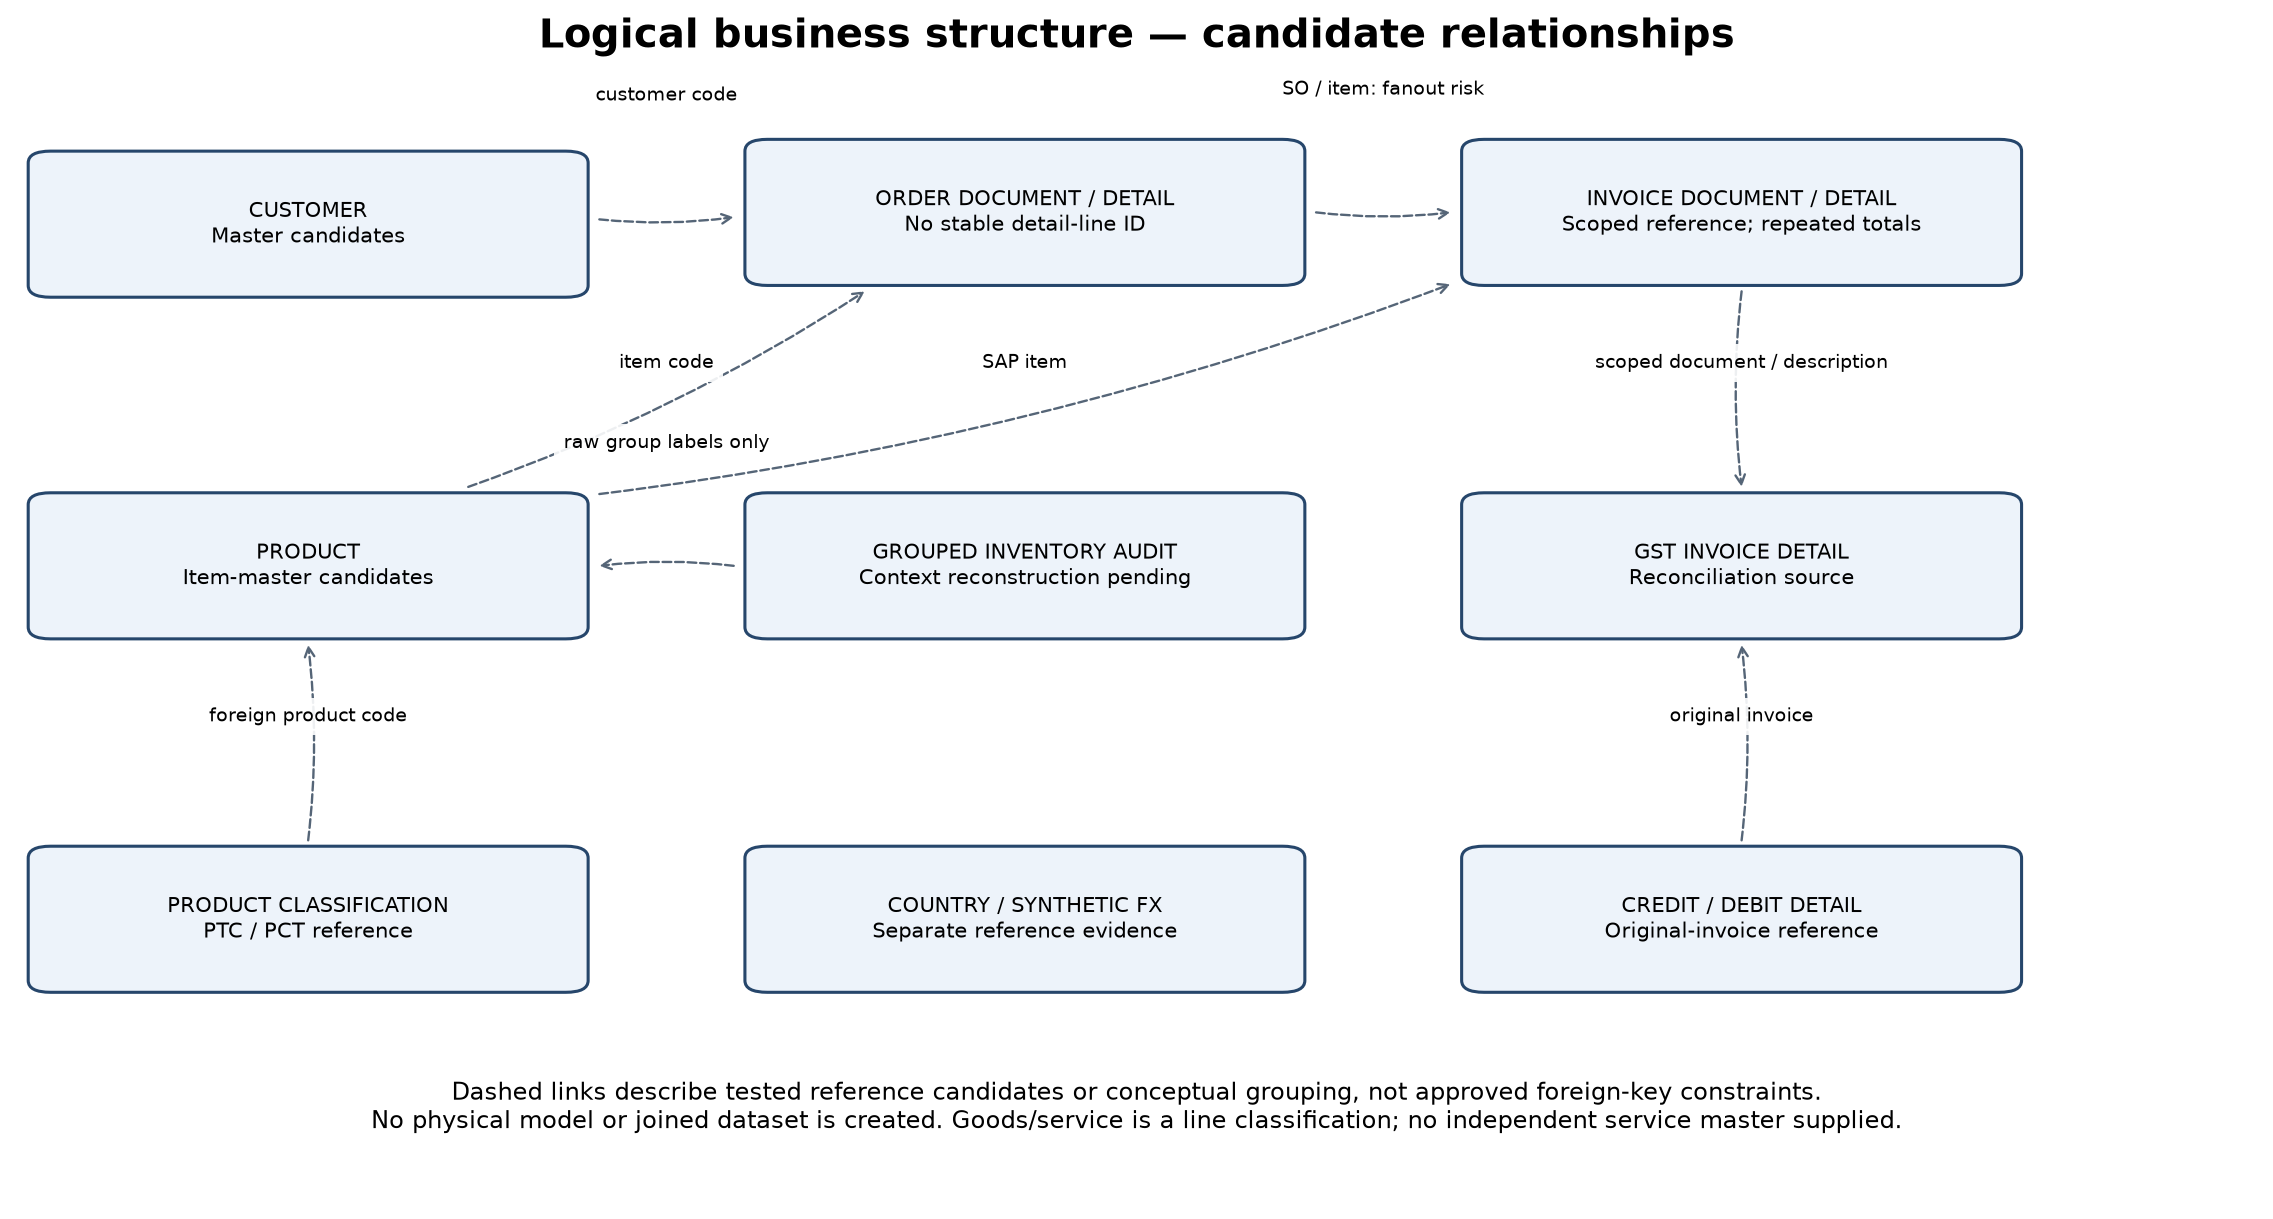

In [10]:
display(Image(filename=str(analysis.out / "data_model_diagram/logical_business_model.png")))

## Conclusions, readiness and validation

The report states conditional row-preserving lookups, joins with demonstrated fanout, separate-source recommendations and questions for NOP. Business target discovery can proceed collaboratively; consolidated preparation and training require approved authority, stable keys/grain, dates and financial rules. Stop here for review.

In [11]:
assert validation["all_protected_hashes_unchanged"]
assert validation["tables"] == 20 and validation["identifier_candidates"] == 135
assert all(c["passed"] for c in validation["checks"])
assert all(c["complete_csv_and_excel_content_verified"] for c in validation["export_checks"])
display(results["export_validation"])
display(Markdown((analysis.out / "dataset_relationship_report.md").read_text(encoding="utf-8")))
print("Analysis complete. No further development activity started.")

,workbook,sheet,rows,columns,complete_csv_and_excel_content_verified
0,dataset_granularity_report.xlsx,dataset_granularity,20,11,True
1,dataset_granularity_report.xlsx,document_context,27,7,True
2,dataset_granularity_report.xlsx,inventory_row_shapes,12,5,True
3,dataset_granularity_report.xlsx,service_indicators,4,7,True
4,identifier_relationship_matrix.xlsx,identifier_profiles,135,26,True
5,identifier_relationship_matrix.xlsx,identifier_formats,145,4,True
6,identifier_relationship_matrix.xlsx,composite_keys,38,16,True
7,identifier_relationship_matrix.xlsx,key_derivation_rules,5,4,True
8,identifier_relationship_matrix.xlsx,key_scope_checks,2,5,True
9,identifier_relationship_matrix.xlsx,relationship_candidates,148,37,True


# Dataset relationship and business structure assessment

Analysis date: 2026-11-02. Scope: 17 files, 14 Excel workbooks / 17 worksheets and 3 GST CSV tables; all 20 tables assessed using the validated inventory headers and complete source columns.

## Executive assessment

The data supports **business target discovery with the NOP team**, but is **not ready for unconditional consolidated preparation or ML**. Technical value overlap is established where reported; no business primary key, foreign-key constraint, source authority or line-level allocation rule has been confirmed. Full raw values were retained, including blank rows and all known duplicate candidates. No permanent join output, cleaning, date correction or model was produced.

135 identifier candidates were profiled across complete columns and reconciled with prior quality counts. 148 directed relationship/key experiments were measured, including all 101 earlier comparisons. 69 complete controlled left joins were executed in bounded memory chunks and independently checked against key-frequency calculations. 27 raw-key directions have observed matches and globally unique nonblank target keys; these are **structurally row-preserving lookup candidates**, conditional on approved authority, semantic identity and unmatched-key handling. 20 raw-key directions demonstrably expand source rows.

## Main evidence and practical implications

- **Order customer lookup:** the small order export matches 1,098 of 1,098 rows to 40 distinct codes in the small customer master without fanout. The large order export matches 90,524 nonblank-key rows against the large master, leaves 9,762 total rows unmatched and expands to 100,898 rows because the target codes repeat. Neither master is automatically authoritative for both extracts.
- **Order product lookup:** the small order export matches 1,062 rows / 120 distinct products to the small item master; 36 rows are unmatched, including missing product codes. Missing product values need service/charge-line confirmation.
- **GST/invoice representation overlap:** raw GST invoice numbers yield only 178 distinct values; explicit prefix/series reconstruction yields 234 scoped documents. All 337 GST rows match the small invoice export. A document-only detail join produces 609 rows from 337; adding raw item description produces 337 rows with 337 unique matching composite values. For each of 6 quantity/base/line-total/GST fields, every compared line-key group is numerically equivalent under the stated diagnostic tolerance, although CSV text versus Excel number types differ. This is strong evidence of corresponding representations in these specific extracts; it is not a stable upstream line-key guarantee or permission to count them twice.
- **Invoice/order fanout:** SO-number linking the large invoice export to the large order export yields 402,400 rows from 100,188; raw-row quantity changes from 363,277.00 to 1,472,651.00. This is join-induced repetition, not new business activity. Invoice-to-order line allocation remains unresolved.
- **Adjustment scope:** the six-row credit/debit file has 3 raw note numbers but 6 scoped note references. The larger file has 243 scoped notes among 276 nonempty rows, with 33 excess repeated scoped keys; 3 additional rows are entirely blank. The two files therefore cannot be assigned identical document/line grain solely from their similar columns. Three excess note-plus-description signatures also remain duplicate candidates.
- **Rate overlap:** two explicit period/currency pairs overlap across the marked synthetic rate files. Their rate values agree on those pairs; one start-date and one end-date comparison differ in raw representation. This is not proof of a different calendar date, and neither synthetic rate source is approved for conversion.
- **Inventory context:** raw item joins reach group labels, while most movement rows have no populated item code. Applying these labels to following rows requires an approved layout rule; the current tests do not reconstruct them.



## Dataset meanings and record grain

Rows below the validated header include completely empty rows. Candidate grain is not inferred from schema similarity alone. Document context variation, key multiplicity, inventory row shape and goods/service indicators are included in the granularity workbook.

| table | row_count | nonempty_rows | column_count | candidate_record_grain | evidence | business_confirmation |
| --- | --- | --- | --- | --- | --- | --- |
| Customer Master Report 1.xlsx :: Sheet1 | 40 | 40 | 35 | Customer-master record candidate; repeated codes in some extracts | Customer code: 40 distinct; 0 excess repeated codes; customer/contact/address/tax attributes. | Business owner must confirm entity scope, extraction filters, history and source authority. |
| Customer Master Report 2.xlsx :: Sheet1 | 5015 | 5012 | 35 | Customer-master record candidate; repeated codes in some extracts | Customer code: 4997 distinct; 15 excess repeated codes; customer/contact/address/tax attributes. | Business owner must confirm entity scope, extraction filters, history and source authority. |
| Exchange Rate 1.xlsx :: INR to JPY | 7 | 7 | 7 | Monthly currency-pair period record candidate | Explicit SYNTHETIC DATA title; monthly period and From/To currency with rate, start/end fields. | Business owner must confirm entity scope, extraction filters, history and source authority. Period applicability, start/end semantics and use of synthetic values require approval; no date-based conversion join attempted. |
| Exchange Rate.xlsx :: INR to JPY | 22 | 22 | 7 | Monthly currency-pair period record candidate | Explicit SYNTHETIC DATA title; monthly period and From/To currency with rate, start/end fields. | Business owner must confirm entity scope, extraction filters, history and source authority. Period applicability, start/end semantics and use of synthetic values require approval; no date-based conversion join attempted. |
| GSTR1_Credit_Debit_Note 1.csv :: (CSV table) | 6 | 6 | 64 | Credit/debit reporting detail candidate; observed rows per scoped note assessed separately | Credit/debit type, note series and original invoice references with item/tax amounts. 6 raw/scoped document identifiers; 0 repeated groups; maximum 1 rows/document. | Business owner must confirm entity scope, extraction filters, history and source authority. One observed row per note does not establish document-level grain; issuer, sign conventions, line completeness and linked original invoices need confirmation. |
| GSTR1_Credit_Debit_Note 2.csv :: (CSV table) | 279 | 276 | 64 | Credit/debit reporting detail candidate; observed rows per scoped note assessed separately | Credit/debit type, note series and original invoice references with item/tax amounts. 243 raw/scoped document identifiers; 31 repeated groups; maximum 3 rows/document. | Business owner must confirm entity scope, extraction filters, history and source authority. One observed row per note does not establish document-level grain; issuer, sign conventions, line completeness and linked original invoices need confirmation. |
| GSTR1_Invoice.csv :: (CSV table) | 337 | 337 | 68 | Tax reporting line candidate, scoped invoice number repeated across lines | Series/prefix/suffix and raw invoice number; item description, GST components, line total versus invoice value. 234 raw/scoped document identifiers; 70 repeated groups; maximum 3 rows/document. | Business owner must confirm entity scope, extraction filters, history and source authority. Raw invoice number omits series/year; GST description/HSN is not a unique product ID; reconcile with invoice export before treating as independent sales. |
| Inventory Audit Report as on 200327.xlsx :: Sheet1 | 108129 | 108124 | 13 | Mixed item labels, opening-balance lines and movement details | 5010 item-labelled rows; 5010 opening balance rows; 98104 movement rows; 98104 movement rows lack raw item. | Business owner must confirm entity scope, extraction filters, history and source authority. Group context is required before movement-to-product mapping; do not sum cumulative/opening and movement values together. Filename dates are unconfirmed. |
| Inventory Audit Report as on 200926 1.xlsx :: Sheet1 | 162 | 162 | 13 | Mixed item labels, opening-balance lines and movement details | 52 item-labelled rows; 52 opening balance rows; 58 movement rows; 58 movement rows lack raw item. | Business owner must confirm entity scope, extraction filters, history and source authority. Group context is required before movement-to-product mapping; do not sum cumulative/opening and movement values together. Filename dates are unconfirmed. |
| Inventory Audit Report as on 200926.xlsx :: Sheet1 | 162 | 162 | 13 | Mixed item labels, opening-balance lines and movement details | 52 item-labelled rows; 52 opening balance rows; 58 movement rows; 58 movement rows lack raw item. | Business owner must confirm entity scope, extraction filters, history and source authority. Group context is required before movement-to-product mapping; do not sum cumulative/opening and movement values together. Filename dates are unconfirmed. |
| Item Master Lists 1.xlsx :: Item Lists | 150 | 150 | 19 | Item-master record candidate with stock and commercial attributes | Item number: 150 distinct; 0 excess repeated codes; descriptions, stock, pricing-unit and classification attributes. | Business owner must confirm entity scope, extraction filters, history and source authority. In Stock/Value are extract attributes; snapshot/as-of and valuation basis unconfirmed. |
| Item Master Lists 2.xlsx :: Item Lists | 5015 | 5012 | 19 | Item-master record candidate with stock and commercial attributes | Item number: 5000 distinct; 12 excess repeated codes; descriptions, stock, pricing-unit and classification attributes. | Business owner must confirm entity scope, extraction filters, history and source authority. In Stock/Value are extract attributes; snapshot/as-of and valuation basis unconfirmed. |
| Sales Invoice Details 1.xlsx :: Sheet1 | 100188 | 100183 | 43 | Invoice goods/service detail candidate with repeated document totals | SAP product, goods/service flag, quantity, line tax/base/total and repeated invoice header fields. 35683 raw/scoped document identifiers; 24867 repeated groups; maximum 7 rows/document. | Business owner must confirm entity scope, extraction filters, history and source authority. No stable invoice-line ID; document total is not additive across detail rows. SO can differ across invoice lines. |
| Sales Invoice Details.xlsx :: Sheet1 | 337 | 337 | 43 | Invoice goods/service detail candidate with repeated document totals | SAP product, goods/service flag, quantity, line tax/base/total and repeated invoice header fields. 234 raw/scoped document identifiers; 70 repeated groups; maximum 3 rows/document. | Business owner must confirm entity scope, extraction filters, history and source authority. No stable invoice-line ID; document total is not additive across detail rows. SO can differ across invoice lines. |
| Sales Order Report 1.xlsx :: Sheet1 | 1098 | 1098 | 26 | Order item/service-like detail record; not one row per order | 299 raw/scoped document identifiers; 284 repeated groups; maximum 9 rows/document. | Business owner must confirm entity scope, extraction filters, history and source authority. No stable order-line ID; repeated SO/item can be legitimate split lines or duplicate extracts; blank item is not proof of service. |
| Sales Order Report 2.xlsx :: Sheet1 | 100286 | 100280 | 26 | Order item/service-like detail record; not one row per order | 32234 raw/scoped document identifiers; 24943 repeated groups; maximum 7 rows/document. | Business owner must confirm entity scope, extraction filters, history and source authority. No stable order-line ID; repeated SO/item can be legitimate split lines or duplicate extracts; blank item is not proof of service. |
| Sales_Order_Data_202609.xlsx :: Customer list | 43 | 43 | 4 | Reference customer row with sparse alternate code and BP_CODE | Explicit SYNTHETIC DATA title; numeric Customer Code and alphanumeric BP_CODE are separate observed domains. | Business owner must confirm entity scope, extraction filters, history and source authority. Do not equate numeric Customer Code with customer-master C-prefixed code; BP mapping coverage must be assessed. |
| Sales_Order_Data_202609.xlsx :: Country master | 11 | 11 | 5 | Country-code row with multilingual names and segment | 11 distinct country codes and country names; multilingual aliases and geographic segment. | Business owner must confirm entity scope, extraction filters, history and source authority. Free-text transaction/master country names need an approved alias mapping; ISO convention is a hypothesis, not an enforced constraint. |
| Sales_Order_Data_202609.xlsx :: PTC_NOPI | 60 | 60 | 8 | Product-code row in agency/product classification list | Unique observed Product code with category, product and middle segments. | Business owner must confirm entity scope, extraction filters, history and source authority. Code namespace and link to foreign product codes need confirmation; unnamed PCT_NOPJ field retained without invented name. |
| Sales_Order_Data_202609.xlsx :: PCT_NOPJ | 33 | 33 | 9 | Product-code row in agency/product classification list | Unique observed Product code with category, product and middle segments. Blank first header has 33 populated values: ["NOPJ"]. | Business owner must confirm entity scope, extraction filters, history and source authority. Code namespace and link to foreign product codes need confirmation; unnamed PCT_NOPJ field retained without invented name. |

## Identifier validation

All 135 candidates include nulls, distinct counts, excess duplicates (`nonblank rows - distinct values`), uniqueness among nonblank rows, source types, format patterns, whitespace and case/trim collision diagnostics. Nulls include structural blank rows; ordinal and descriptive/contact candidates remain explicitly distinguished from business identifiers. Full matching coverage is in `identifier_match_detail` and `relationship_candidates` sheets, not estimated from samples. Keys with null components do not match each other.

Observed entity/reference candidates unique among their populated values (completeness and business scope still required):

| table | column_name | null_rows | distinct_values | nonblank_uniqueness_percent | complete_and_unique |
| --- | --- | --- | --- | --- | --- |
| Customer Master Report 1.xlsx :: Sheet1 | CUSTOMER CODE | 0 | 40 | 100.0 | True |
| GSTR1_Credit_Debit_Note 1.csv :: (CSV table) | Invoice_Number | 0 | 6 | 100.0 | True |
| Inventory Audit Report as on 200327.xlsx :: Sheet1 |  Item No.  | 103119 | 5010 | 100.0 | False |
| Inventory Audit Report as on 200926 1.xlsx :: Sheet1 | Item No. | 110 | 52 | 100.0 | False |
| Inventory Audit Report as on 200926.xlsx :: Sheet1 | Item No. | 110 | 52 | 100.0 | False |
| Item Master Lists 1.xlsx :: Item Lists | Item No. | 0 | 150 | 100.0 | True |
| Item Master Lists 1.xlsx :: Item Lists | foreign Code | 47 | 103 | 100.0 | False |
| Sales_Order_Data_202609.xlsx :: Customer list | Customer Code | 40 | 3 | 100.0 | False |
| Sales_Order_Data_202609.xlsx :: Customer list | BP_CODE | 6 | 37 | 100.0 | False |
| Sales_Order_Data_202609.xlsx :: Country master | Code | 0 | 11 | 100.0 | True |
| Sales_Order_Data_202609.xlsx :: PTC_NOPI | Product code | 0 | 60 | 100.0 | True |
| Sales_Order_Data_202609.xlsx :: PCT_NOPJ | Product code | 0 | 33 | 100.0 | True |

Composite keys were tested across the full tables. Document+product or document+description uniqueness is diagnostic only: it cannot establish stable line identity, especially for partial fulfilment, repeated products, service lines, amendments or reused series. See `composite_keys` for all counts. GST invoice scoped keys are reconstructed **only in diagnostic copies** using prefix + series + number + suffix. Credit/debit scoped references use prefix + suffix + note number; raw note numbers can repeat across CN/DN/year series. No ambiguous transaction date participates in a key.

## Supported reference evidence and controlled joins

The complete matrix contains source and target columns, null/eligible counts, distinct and row coverage in both directions, unmatched records, expected versus observed cardinality, predicted fanout, technical confidence and unresolved questions. Relationships are retained even when no matches are found. Old same-family comparisons are exploratory overlaps, not automatically business edges; customer reference numbers, invoice raw numbers and foreign-code namespaces require semantic scope.

### Row-preserving lookup candidates on current raw keys

These preserve all left rows, including unmatched/null keys. They do not certify customer/product identity, correct source values, tax-registration uniqueness in business terms or completeness of coverage. Only eligible target keys are required unique; blank target keys are excluded.

| relationship_id | source_table | source_column | target_table | target_column | matching_source_records | unmatched_source_records | source_distinct_coverage_percent |
| --- | --- | --- | --- | --- | --- | --- | --- |
| REL-021 | Inventory Audit Report as on 200327.xlsx :: Sheet1 | [" Item No. "] | Item Master Lists 1.xlsx :: Item Lists | ["Item No."] | 142 | 107987 | 2.8343 |
| REL-028 | Inventory Audit Report as on 200926 1.xlsx :: Sheet1 | ["Item No."] | Item Master Lists 1.xlsx :: Item Lists | ["Item No."] | 40 | 122 | 76.9231 |
| REL-034 | Inventory Audit Report as on 200926.xlsx :: Sheet1 | ["Item No."] | Item Master Lists 1.xlsx :: Item Lists | ["Item No."] | 52 | 110 | 100.0 |
| REL-050 | Item Master Lists 1.xlsx :: Item Lists | ["foreign Code"] | Sales_Order_Data_202609.xlsx :: PTC_NOPI | ["Product code"] | 60 | 90 | 58.2524 |
| REL-051 | Item Master Lists 1.xlsx :: Item Lists | ["foreign Code"] | Sales_Order_Data_202609.xlsx :: PCT_NOPJ | ["Product code"] | 33 | 117 | 32.0388 |
| REL-060 | Item Master Lists 2.xlsx :: Item Lists | ["foreign Code"] | Sales_Order_Data_202609.xlsx :: PTC_NOPI | ["Product code"] | 60 | 4955 | 2.0422 |
| REL-061 | Item Master Lists 2.xlsx :: Item Lists | ["foreign Code"] | Sales_Order_Data_202609.xlsx :: PCT_NOPJ | ["Product code"] | 33 | 4982 | 1.1232 |
| REL-075 | Sales Invoice Details 1.xlsx :: Sheet1 | ["Item Foreign Code"] | Sales_Order_Data_202609.xlsx :: PTC_NOPI | ["Product code"] | 1371 | 98817 | 1.29 |
| REL-076 | Sales Invoice Details 1.xlsx :: Sheet1 | ["Item Foreign Code"] | Sales_Order_Data_202609.xlsx :: PCT_NOPJ | ["Product code"] | 632 | 99556 | 0.7095 |
| REL-085 | Sales Invoice Details.xlsx :: Sheet1 | ["Item Foreign Code"] | Sales_Order_Data_202609.xlsx :: PTC_NOPI | ["Product code"] | 165 | 172 | 58.5106 |
| REL-086 | Sales Invoice Details.xlsx :: Sheet1 | ["Item Foreign Code"] | Sales_Order_Data_202609.xlsx :: PCT_NOPJ | ["Product code"] | 93 | 244 | 32.9787 |
| REL-102 | Sales Order Report 1.xlsx :: Sheet1 | ["Customer Code"] | Customer Master Report 1.xlsx :: Sheet1 | ["CUSTOMER CODE"] | 1098 | 0 | 100.0 |
| REL-106 | Sales Order Report 1.xlsx :: Sheet1 | ["Item No"] | Item Master Lists 1.xlsx :: Item Lists | ["Item No."] | 1062 | 36 | 100.0 |
| REL-108 | Sales Order Report 2.xlsx :: Sheet1 | [" Customer Code "] | Customer Master Report 1.xlsx :: Sheet1 | ["CUSTOMER CODE"] | 613 | 99673 | 0.5445 |
| REL-112 | Sales Order Report 2.xlsx :: Sheet1 | ["Item No"] | Item Master Lists 1.xlsx :: Item Lists | ["Item No."] | 2388 | 97898 | 1.6298 |
| REL-114 | Sales Invoice Details 1.xlsx :: Sheet1 | ["Part Code SAP Code"] | Item Master Lists 1.xlsx :: Item Lists | ["Item No."] | 2395 | 97793 | 1.6351 |
| REL-116 | Sales Invoice Details 1.xlsx :: Sheet1 | ["Customer Billing GSTIN"] | Customer Master Report 1.xlsx :: Sheet1 | ["GSTIN"] | 260 | 99928 | 0.6054 |
| REL-125 | Sales Invoice Details.xlsx :: Sheet1 | ["Part Code SAP Code"] | Item Master Lists 1.xlsx :: Item Lists | ["Item No."] | 323 | 14 | 100.0 |
| REL-127 | Sales Invoice Details.xlsx :: Sheet1 | ["Customer Billing GSTIN"] | Customer Master Report 1.xlsx :: Sheet1 | ["GSTIN"] | 278 | 59 | 100.0 |
| REL-132 | GSTR1_Invoice.csv :: (CSV table) | ["@scoped_invoice", "Item_Description"] | Sales Invoice Details.xlsx :: Sheet1 | ["Invoice Num", "Item Description"] | 337 | 0 | 100.0 |
| REL-136 | Sales_Order_Data_202609.xlsx :: Customer list | ["BP_CODE"] | Customer Master Report 1.xlsx :: Sheet1 | ["CUSTOMER CODE"] | 37 | 6 | 100.0 |
| REL-137 | Customer Master Report 1.xlsx :: Sheet1 | ["Bill-to Country"] | Sales_Order_Data_202609.xlsx :: Country master | ["Country Name"] | 4 | 36 | 33.3333 |
| REL-138 | GSTR1_Invoice.csv :: (CSV table) | ["Customer_Bill_To_GSTIN"] | Customer Master Report 1.xlsx :: Sheet1 | ["GSTIN"] | 278 | 59 | 100.0 |
| REL-139 | GSTR1_Credit_Debit_Note 1.csv :: (CSV table) | ["Customer_Bill_To_GSTIN"] | Customer Master Report 1.xlsx :: Sheet1 | ["GSTIN"] | 6 | 0 | 100.0 |
| REL-140 | GSTR1_Credit_Debit_Note 2.csv :: (CSV table) | ["Customer_Bill_To_GSTIN"] | Customer Master Report 1.xlsx :: Sheet1 | ["GSTIN"] | 37 | 242 | 14.2857 |
| REL-142 | Customer Master Report 2.xlsx :: Sheet1 | ["Bill-to Country"] | Sales_Order_Data_202609.xlsx :: Country master | ["Country Name"] | 305 | 4710 | 12.5 |
| REL-148 | Exchange Rate 1.xlsx :: INR to JPY | ["@explicit_month_period", "From Currency", "To Currency"] | Exchange Rate.xlsx :: INR to JPY | ["@explicit_month_period", "From Currency", "To Currency"] | 2 | 5 | 28.5714 |

### Joins with observed duplicate expansion

| relationship_id | source_table | source_column | target_table | target_column | observed_cardinality | source_rows | predicted_left_join_rows | predicted_excess_left_rows |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| REL-013 | GSTR1_Credit_Debit_Note 1.csv :: (CSV table) | ["Invoice_Number"] | Sales Invoice Details.xlsx :: Sheet1 | ["Invoice Num"] | one-to-many | 6 | 14 | 8 |
| REL-015 | GSTR1_Credit_Debit_Note 2.csv :: (CSV table) | ["Invoice_Number"] | Sales Invoice Details 1.xlsx :: Sheet1 | ["Invoice Num"] | many-to-many | 279 | 873 | 594 |
| REL-016 | GSTR1_Credit_Debit_Note 2.csv :: (CSV table) | ["Invoice_Number"] | Sales Invoice Details.xlsx :: Sheet1 | ["Invoice Num"] | many-to-many | 279 | 310 | 31 |
| REL-022 | Inventory Audit Report as on 200327.xlsx :: Sheet1 | [" Item No. "] | Item Master Lists 2.xlsx :: Item Lists | ["Item No."] | one-to-many | 108129 | 108141 | 12 |
| REL-063 | Sales Invoice Details 1.xlsx :: Sheet1 | ["SO Num"] | Sales Order Report 1.xlsx :: Sheet1 | ["SO No"] | many-to-many | 100188 | 101376 | 1188 |
| REL-064 | Sales Invoice Details 1.xlsx :: Sheet1 | ["SO Num"] | Sales Order Report 2.xlsx :: Sheet1 | ["SO No"] | many-to-many | 100188 | 402400 | 302212 |
| REL-077 | Sales Invoice Details.xlsx :: Sheet1 | ["SO Num"] | Sales Order Report 1.xlsx :: Sheet1 | ["SO No"] | many-to-many | 337 | 1347 | 1010 |
| REL-078 | Sales Invoice Details.xlsx :: Sheet1 | ["SO Num"] | Sales Order Report 2.xlsx :: Sheet1 | ["SO No"] | many-to-many | 337 | 730 | 393 |
| REL-110 | Sales Order Report 2.xlsx :: Sheet1 | [" Customer Code "] | Customer Master Report 2.xlsx :: Sheet1 | ["CUSTOMER CODE"] | many-to-many | 100286 | 100898 | 612 |
| REL-113 | Sales Order Report 2.xlsx :: Sheet1 | ["Item No"] | Item Master Lists 2.xlsx :: Item Lists | ["Item No."] | many-to-many | 100286 | 100629 | 343 |
| REL-115 | Sales Invoice Details 1.xlsx :: Sheet1 | ["Part Code SAP Code"] | Item Master Lists 2.xlsx :: Item Lists | ["Item No."] | many-to-many | 100188 | 100528 | 340 |
| REL-117 | Sales Invoice Details 1.xlsx :: Sheet1 | ["Customer Billing GSTIN"] | Customer Master Report 2.xlsx :: Sheet1 | ["GSTIN"] | many-to-many | 100188 | 100816 | 628 |
| REL-118 | Sales Invoice Details 1.xlsx :: Sheet1 | ["SO Num", "Part Code SAP Code"] | Sales Order Report 1.xlsx :: Sheet1 | ["SO No", "Item No"] | many-to-many | 100188 | 100189 | 1 |
| REL-119 | Sales Invoice Details 1.xlsx :: Sheet1 | ["SO Num", "Part Code SAP Code"] | Sales Order Report 2.xlsx :: Sheet1 | ["SO No", "Item No"] | many-to-many | 100188 | 100238 | 50 |
| REL-120 | GSTR1_Invoice.csv :: (CSV table) | ["@scoped_invoice"] | Sales Invoice Details 1.xlsx :: Sheet1 | ["Invoice Num"] | many-to-many | 337 | 344 | 7 |
| REL-129 | Sales Invoice Details.xlsx :: Sheet1 | ["SO Num", "Part Code SAP Code"] | Sales Order Report 1.xlsx :: Sheet1 | ["SO No", "Item No"] | many-to-many | 337 | 340 | 3 |
| REL-131 | GSTR1_Invoice.csv :: (CSV table) | ["@scoped_invoice"] | Sales Invoice Details.xlsx :: Sheet1 | ["Invoice Num"] | many-to-many | 337 | 609 | 272 |
| REL-145 | GSTR1_Credit_Debit_Note 2.csv :: (CSV table) | ["Customer_Bill_To_GSTIN"] | Customer Master Report 2.xlsx :: Sheet1 | ["GSTIN"] | many-to-many | 279 | 281 | 2 |
| REL-146 | GSTR1_Credit_Debit_Note 1.csv :: (CSV table) | ["Invoice_Number"] | GSTR1_Invoice.csv :: (CSV table) | ["@scoped_invoice"] | one-to-many | 6 | 14 | 8 |
| REL-147 | GSTR1_Credit_Debit_Note 2.csv :: (CSV table) | ["Invoice_Number"] | GSTR1_Invoice.csv :: (CSV table) | ["@scoped_invoice"] | many-to-many | 279 | 310 | 31 |

Order and invoice exports contain detail rows, so SO-number equality alone is not a line relationship. Adding product reduces ambiguity but does not establish fulfilment allocation. GST and Excel invoice lines may be alternate representations of the same document; document equality can expand line counts. Credit/debit references point to a document, not an established invoice line. Retain separate order, invoice and tax/adjustment facts until stable keys or approved allocation/reconciliation rules exist.

### Financial and quantity controls

Every executed join records original/source/target row counts, actual left/inner row counts, unmatched records, distinct key counts before/after and per-row copy multiplicities. `join_financial_effects` contains source/target raw-row sums before/after, sums of absolute values to expose offsetting signed amounts, numeric parse failures and selected target totals before replication. All input rows are used; no sampled joins. Target-side totals after a left join exclude unmatched target rows, then repeat matched rows according to source-key multiplicity.

Document totals (`Invoice Total Include GST`, `Invoice_Value`, credit/debit document value), inventory cumulative values and opening balances are **not additive line measures**. Their mechanical row sums illustrate fanout only and are never presented as business revenue, inventory balance or tax liability. Quantity/line amounts also require currency/unit/sign confirmation. Prior financial exceptions remain unresolved; numerical equivalence tolerances in attribute-set comparisons are 0.01 absolute / 1e-9 relative and do not validate accounting. Diagnostics may interpret numeric text via the existing documented quality parser; unparsable values remain excluded and counted, never replaced with business zeros.

## Source overlap, conflicts and authority

`source_overlap` compares full raw typed payloads after excluding export ordinals for identical normalized header schemas. Counts include distinct common payloads, rows on each side and multiset intersection. This proves observed overlap only; historical snapshots, duplicate extracts, generated variants and common origin remain hypotheses. `attribute_conflicts` compares complete sets of nonblank raw attributes within matching keys, reports formatting-only/numeric-equivalent discrepancies separately, and never chooses a winning value. Set agreement does not prove individual line correspondence.

| source_table | target_table | evidence_type | distinct_payloads_source | distinct_payloads_target | matching_payloads | source_rows_with_payload_in_target | target_rows_with_payload_in_source | multiset_intersection_rows | row_ordinals_excluded | conclusion |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Customer Master Report 1.xlsx :: Sheet1 | Customer Master Report 2.xlsx :: Sheet1 | Complete raw typed payload comparison | 40 | 4997 | 5 | 5 | 5 | 5 | True | Observed overlapping extract content; duplicate extract/snapshot/common origin is a hypothesis. No source precedence established. |
| Exchange Rate 1.xlsx :: INR to JPY | Exchange Rate.xlsx :: INR to JPY | Complete raw typed payload comparison | 7 | 22 | 0 | 0 | 0 | 0 | True | No exact raw typed payload overlap. This does not exclude related/generated/history extracts with changed values or encodings; no source authority established. |
| GSTR1_Credit_Debit_Note 1.csv :: (CSV table) | GSTR1_Credit_Debit_Note 2.csv :: (CSV table) | Complete raw typed payload comparison | 6 | 273 | 0 | 0 | 0 | 0 | True | No exact raw typed payload overlap. This does not exclude related/generated/history extracts with changed values or encodings; no source authority established. |
| Inventory Audit Report as on 200327.xlsx :: Sheet1 | Inventory Audit Report as on 200926 1.xlsx :: Sheet1 | Complete raw typed payload comparison | 107325 | 154 | 7 | 341 | 15 | 15 | True | Observed overlapping extract content; duplicate extract/snapshot/common origin is a hypothesis. No source precedence established. |
| Inventory Audit Report as on 200327.xlsx :: Sheet1 | Inventory Audit Report as on 200926.xlsx :: Sheet1 | Complete raw typed payload comparison | 107325 | 147 | 11 | 337 | 26 | 26 | True | Observed overlapping extract content; duplicate extract/snapshot/common origin is a hypothesis. No source precedence established. |
| Inventory Audit Report as on 200926 1.xlsx :: Sheet1 | Inventory Audit Report as on 200926.xlsx :: Sheet1 | Complete raw typed payload comparison | 154 | 147 | 51 | 58 | 66 | 58 | True | Observed overlapping extract content; duplicate extract/snapshot/common origin is a hypothesis. No source precedence established. |
| Item Master Lists 1.xlsx :: Item Lists | Item Master Lists 2.xlsx :: Item Lists | Complete raw typed payload comparison | 150 | 5000 | 16 | 16 | 16 | 16 | True | Observed overlapping extract content; duplicate extract/snapshot/common origin is a hypothesis. No source precedence established. |
| Sales Invoice Details 1.xlsx :: Sheet1 | Sales Invoice Details.xlsx :: Sheet1 | Complete raw typed payload comparison | 100123 | 337 | 0 | 0 | 0 | 0 | True | No exact raw typed payload overlap. This does not exclude related/generated/history extracts with changed values or encodings; no source authority established. |
| Sales Order Report 1.xlsx :: Sheet1 | Sales Order Report 2.xlsx :: Sheet1 | Complete raw typed payload comparison | 1098 | 100220 | 1 | 1 | 1 | 1 | True | Observed overlapping extract content; duplicate extract/snapshot/common origin is a hypothesis. No source precedence established. |

| domain | candidate_source | evidence | decision |
| --- | --- | --- | --- |
| Customers | Customer Master Reports; Customer list only as candidate BP crosswalk | Customer attributes and business codes; complete and partial overlaps measured | No authoritative source confirmed; versions conflict and reference list is explicitly synthetic |
| Products | Item Master Lists; PTC_NOPI/PCT_NOPJ classifications | SAP item and foreign product namespaces; classifications are separate reference lists | No authoritative version/crosswalk confirmed; large master has repeated codes |
| Orders | Sales Order Report exports | SO references, customer/product, quantities and line values | Potential order detail fact sources; scope, history, stable line ID and extract precedence required |
| Sales/invoices | Sales Invoice Details; GST invoice as reconciliation source | Invoice line measures and scoped GST document identifiers with observed overlap | Keep sources separate; do not stack overlapping invoice/GST rows as additional sales |
| GST/adjustments | GSTR1 Invoice and Credit/Debit Note CSVs | Reporting fields, series, tax amounts and original invoice references | Candidate tax/adjustment evidence only; filing version, acceptance status and sign basis unknown |
| Inventory | Three inventory audit exports | Grouped item labels, opening balances, document movements and cumulative measures | Require approved grouped-layout reconstruction and snapshot scope before movement fact construction |
| Currency/country/service | Synthetic rate periods; country reference; G/S invoice lines | Two explicit synthetic rate titles; multilingual country list; goods/service flag | No production FX authority or independent service master established; approve aliases and service definition |

Explicit SYNTHETIC DATA markers are retained for the two exchange-rate sheets and reference Customer list. Example-domain contact values are additional sample indicators, not proof every source is synthetic. No largest/newest-file authority rule is applied. Inventory filename dates and reference update dates do not prove transactional snapshot scope. Overlapping monthly exchange rates are compared by explicit period/currency; neither marked synthetic rate table is approved for production conversion. Transaction-date FX joins were intentionally not attempted while formats and applicability remain unresolved.

## Existing quality findings preserved

| issue | prior_affected_count | relationship_impact | status |
| --- | --- | --- | --- |
| Ambiguous dates | 203455.0 | Date equality/order and temporal scope cannot be trusted without approved source-specific formats; no date join executed. | Unresolved; preserved; no records corrected or deleted |
| Impossible dates | 28.0 | Temporal joins and document chronology may fail; preserve tokens for owner correction. | Unresolved; preserved; no records corrected or deleted |
| Possible Excel serial dates | 14949.0 | Numeric values are unconfirmed date encodings; not used as dates or inferred periods. | Unresolved; preserved; no records corrected or deleted |
| Excess exact duplicate rows | 3.0 | Can multiply relationship counts and financial totals; retained in every full-data join. | Unresolved; preserved; no records corrected or deleted |
| Payload-duplicate candidates | 972.0 | Can expand keys; inventory repeated layout rows may be legitimate. No deduplication performed. | Unresolved; preserved; no records corrected or deleted |
| Financial exceptions | nan | Unresolved unit, discount, freight and GST rules limit business reconciliation; mechanical fanout sums do not validate accounting. | Unresolved; preserved; no records corrected or deleted |
| Synthetic indicators | nan | High identifier overlap in sample material does not establish production validity or source authority. | Unresolved; preserved; no records corrected or deleted |
| Unnamed PCT_NOPJ field | 33.0 | 33 populated NOPJ values; likely agency/source context is a hypothesis. Original blank header retained. | Unresolved; preserved; no records corrected or deleted |
| Unconfirmed business identifiers | 135.0 | Empirical uniqueness and coverage are not approved company/year/entity scope or primary/foreign-key constraints. | Unresolved; preserved; no records corrected or deleted |

All 424 prior issue-register entries are carried forward with original source/column/rule counts and severity in the matrix and `prior_issue_register.csv`; issue counts can overlap. No resolution status is upgraded by this analysis. The PCT_NOPJ blank first header remains blank; its 33 `NOPJ` values suggest agency/source context but this interpretation requires manual confirmation. Inventory sparse item labels were not filled down.

## Proposed logical business model

[Logical business model PNG](data_model_diagram/logical_business_model.png) · [SVG](data_model_diagram/logical_business_model.svg) · [Mermaid source](data_model_diagram/logical_business_model.mmd).

Customer and item-master records are potential dimension inputs after source authority, uniqueness and history are approved. Product classifications form separate manufacturer/agency reference candidates. Orders and invoices are separate document/detail concepts; transaction detail facts are possible only after stable line identity and grain are established. GST invoice detail is a reconciliation/reporting representation, and credit/debit detail is an adjustment fact candidate with explicit original-document references and unconfirmed sign conventions. Inventory remains a grouped report requiring approved context reconstruction before movement facts can be defined. Country reference needs an approved alias mapping. Marked synthetic FX periods remain separate. Goods/service flags support a line classification; no independent service entity/master has been demonstrated. A single star schema is not justified at present.

## Decisions and NOP-team questions

1. Which files are production exports, test/synthetic examples or generated variants? What system, company, extraction filters, reporting period and snapshot/version apply to each? Who owns each source of truth?
2. Are customer and product codes globally scoped, or company/branch/version specific? What do alternate numeric Customer Code, BP_CODE, foreign codes and PTC/PCT namespaces mean? Can multiple accounts share GSTIN?
3. What stable order-line and invoice-line IDs exist upstream? Do SO/invoice references include company/year/series scope, and can invoices span orders? How are partial deliveries, repeated products and adjustments allocated?
4. Are GST invoice and Excel invoice rows alternate exports of the same sale? Confirm series reconstruction, filing/revision status, document totals versus line totals, CN/DN signs and original-invoice relationships.
5. Which source-specific date formats and Excel serial epochs are correct? Confirm the monthly 2027-03 period and treatment of impossible tokens; no ambiguous values have been automatically converted.
6. How should inventory group labels, opening balances and cumulative fields be interpreted? Confirm report date labels and whether movement identifiers are unique within warehouse/item scope.
7. Confirm service/charge lines, blank item codes, the unnamed PCT_NOPJ field, country aliases, currency/units, discounts/freight/tax rules and the existing financial exceptions.

**Preparation readiness:** proceed to collaborative business-target analysis using separate source summaries and this evidence. Consolidation and training require explicit approval of source authority, keys/grain, date rules, duplicate treatment, financial reconciliation and join allocation. No next development activity has been started.

## Reproducibility, validation and limitations

- Executable workflow: `notebooks/03_dataset_relationship_analysis.ipynb`; reusable engine: `src/data/analyze_relationships.py`.
- Full outputs: [identifier and relationship matrix](identifier_relationship_matrix.xlsx), [granularity evidence](dataset_granularity_report.xlsx); complete aggregate CSVs accompany workbook sheets.
- All 20 table extents, headers and blank-row counts reconcile with inventory. All 135 identifier null/distinct/duplicate metrics and all 101 prior overlap calculations reconcile with quality evidence.
- Actual pandas join row multiplicities and target row accounting are independently checked against complete key counters. No source rows are discarded, and no null-to-null match is permitted.
- Workbook sheet manifests and every exported aggregate cell are read back and checked against memory and CSV outputs. PNG/SVG diagrams decode successfully. Source and prior-report SHA-256 comparisons are in `protected_file_integrity.csv`; final checks are in `analysis_validation.json` and notebook execution status in `notebook_execution_validation.json`.
- Limitations are business semantics, source authenticity/authority, time interpretation, missing stable line keys, inventory context and unresolved quality exceptions. Name similarity alone does not establish a relationship; matching values alone do not establish a business constraint. Analysis does not validate GST law or accounting treatment.


Analysis complete. No further development activity started.
